# <center> Подбор гиперпараметров



**Что сделаем:**
- кратко вспомним, зачем вообще подбирать гиперпараметры;
- посмотрим, почему `GridSearch` уже не модно, а `Optuna` — да;
- разберём мини-пример на игрушечной функции (чтобы понять механику `Optuna`);
- загрузим churn-датасет и сделаем корректное разбиение `train / val / OOT` по времени;
- соберём baseline-модель `CatBoostClassifier`;
- настроим **большой перебор гиперпараметров CatBoost через Optuna** (много параметров, как в боевых задачах);
- построим визуализации результатов подбора;
- реализуем кастомную метрику с штрафом за переобучение и сравним её с обычным AUC-тюнингом.

---

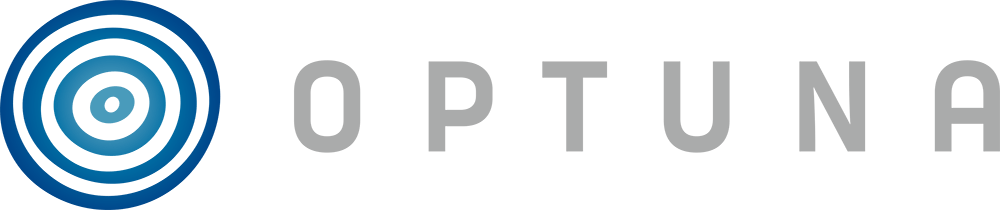

## 1. Подготовка окружения и библиотек

### Полезные ссылки по библиотекам

- Документация Optuna: https://optuna.org/
- Документация по визуализации Optuna: https://optuna.readthedocs.io/en/stable/reference/visualization.html


In [1]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=Warning)

In [2]:
# !pip install optuna catboost -q

import numpy as np
import pandas as pd

import optuna
from optuna import Trial
from optuna.samplers import TPESampler

from catboost import CatBoostClassifier

from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split

import matplotlib.pyplot as plt

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option('display.max_columns', 50)


## 2. Зачем подбирать гиперпараметры и чем плох GridSearch?

**Идея:** гиперпараметры задают "характер" модели — насколько она сложная, как сильно регуляризуется, как агрессивно учится и т.д. Неподобранные гиперпараметры = недообучение или переобучение.

### 2.1. Популярные подходы
- `GridSearch` — полный перебор по сетке значений (дорого, плохо масштабируется).
- `RandomSearch` — случайный перебор (лучше, но всё ещё "слепой")
- Байесовская оптимизация (`Optuna`, `Hyperopt`, `BayesSearchCV`) — учится на прошлых запусках и умнее выбирает новые комбинации.

### 2.2. Почему не GridSearch
- количество комбинаций растёт экспоненциально;
- приходится заранее жёстко задавать сетку;
- огромная часть комбинаций заведомо бесполезна.

### 2.3. Почему Optuna
- умный sampler (`TPE`) вместо тупого перебора;
- удобный API `objective(trial)`;
- встроенный ранний останов прогона (pruners);
- классные визуализации из коробки.

Дальше посмотрим на мини-пример, как `Optuna` ищет минимум простой функции.

## 3. Мини-пример: оптимизация игрушечной функции

Для начала потренируемся на простой функции одной переменной, чтобы увидеть, как `Optuna` обходит пространство поиска.

Возьмём, например, функцию с несколькими локальными минимумами.

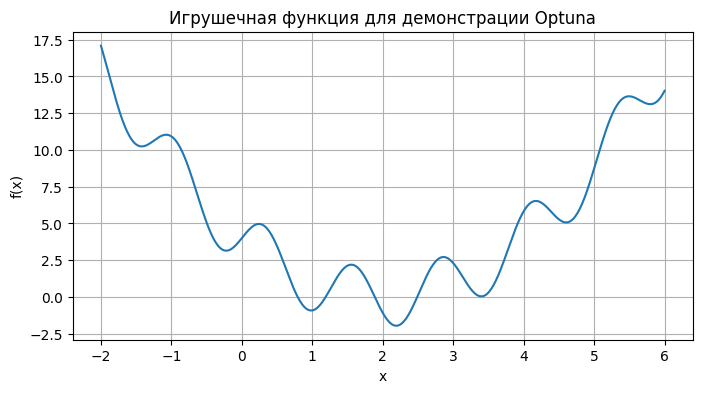

In [3]:
# Игрушечная функция одной переменной
def toy_function(x: float) -> float:
    # Немного искусственная функция с несколькими локальными минимумами
    return (x - 2) ** 2 + np.sin(5 * x) * 2

# Нарисуем её
x_grid = np.linspace(-2, 6, 500)
y_grid = [toy_function(x) for x in x_grid]

plt.figure(figsize=(8, 4))
plt.plot(x_grid, y_grid)
plt.title('Игрушечная функция для демонстрации Optuna')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.grid(True)
plt.show()

In [4]:
def toy_objective(trial: Trial) -> float:
    # Ищем минимум функции на отрезке [-2, 6]
    x = trial.suggest_float('x', -2.0, 6.0)
    value = toy_function(x)
    return value

optuna.logging.set_verbosity(optuna.logging.WARNING)

study_toy = optuna.create_study(direction='minimize', sampler=TPESampler(seed=RANDOM_STATE))
study_toy.optimize(toy_objective, n_trials=100)

print('Лучшее значение функции:', study_toy.best_value)
print('Лучший x:', study_toy.best_params['x'])

Лучшее значение функции: -1.961197108593672
Лучший x: 2.1965745906219003


### 3.1. Визуализация работы Optuna на игрушечной функции

In [5]:
from optuna.visualization import plot_optimization_history, plot_param_importances

plot_optimization_history(study_toy)

In [6]:
optuna.visualization.plot_slice(study_toy)

## 4. Загрузка churn-датасета и временное разбиение train / val / OOT

Теперь переходим к **реальной задаче** — предсказанию оттока клиентов.
Датасет содержит множество агрегированных признаков по клиенту и флаг `target_churn_next` — уйдёт ли клиент в следующем периоде.

Важно: разбиение делаем **по времени**, используя колонку `snapshot_month`, а не случайным образом — так имитируем работу в продакшене.

In [25]:
# url = 'https://raw.githubusercontent.com/totiela/stepik_simulator_ds/main/lessons/lesson_4_1/4_1_churn_dataset.csv'
# df = pd.read_csv(url)

# df.head()

In [24]:
df = pd.read_csv('content/4_1_churn_dataset.csv')

df.head()

,snapshot_month,client_id,n_contacts,n_success_calls,n_fail_calls,n_sms,n_emails,bal_min_30d,bal_max_30d,bal_avg_30d,amt_sum_30d,risk_score,engagement_score,days_since_last_txn,is_term_deposit,is_credit_active,is_mobile_app_user,is_salary_client,target_churn_next
0,2025-10-31,C018653,3,1,2,2,3,9192.264947,18230.532020,12838.831495,3795.755403,67.849181,51.079443,59,1,1,1,0,0
1,2025-04-30,C013674,0,0,0,2,2,7216.543207,16477.091488,12132.905511,6015.803618,45.424803,59.016332,45,0,0,1,1,0
2,2025-06-30,C000095,7,3,4,5,2,6652.732407,11878.617645,9497.440741,3411.792130,19.435547,48.202613,53,0,0,1,1,0
3,2025-08-31,C024552,2,1,1,2,1,7326.576784,9847.075692,8915.166944,6379.017017,19.751387,65.118183,39,0,0,1,1,0
4,2025-01-31,C018243,2,1,1,2,2,7280.467732,18736.986215,13000.502866,6533.976586,60.280657,73.401334,38,1,1,1,1,0


In [8]:
df['target_churn_next'].value_counts(normalize=True)

target_churn_next
0    0.9396
1    0.0604
Name: proportion, dtype: float64

### 4.1. Временное разбиение по квантилям 0.6 и 0.8

In [9]:
# Приводим к типу datetime
df['snapshot_month'] = pd.to_datetime(df['snapshot_month'])

# Считаем квантили 0.6 и 0.8
q60 = df['snapshot_month'].quantile(0.60)
q80 = df['snapshot_month'].quantile(0.80)

print('60% квантиль:', q60)
print('80% квантиль:', q80)

# Разделяем на подвыборки
train_df = df[df['snapshot_month'] <= q60].copy()
val_df   = df[(df['snapshot_month'] > q60) & (df['snapshot_month'] <= q80)].copy()
oot_df   = df[df['snapshot_month'] > q80].copy()

print('Train shape:', train_df.shape)
print('Val shape:  ', val_df.shape)
print('OOT shape:  ', oot_df.shape)

60% квантиль: 2025-06-30 00:00:00
80% квантиль: 2025-08-31 00:00:00
Train shape: (60392, 19)
Val shape:   (19650, 19)
OOT shape:   (19958, 19)


In [10]:
print('Train:', train_df['snapshot_month'].min(), '→', train_df['snapshot_month'].max())
print('Val:  ', val_df['snapshot_month'].min(),   '→', val_df['snapshot_month'].max())
print('OOT:  ', oot_df['snapshot_month'].min(),   '→', oot_df['snapshot_month'].max())

Train: 2025-01-31 00:00:00 → 2025-06-30 00:00:00
Val:   2025-07-31 00:00:00 → 2025-08-31 00:00:00
OOT:   2025-09-30 00:00:00 → 2025-10-31 00:00:00


### 4.2. Подготовка признаков и цели

In [11]:
target_col = 'target_churn_next'
drop_cols = ['client_id', 'snapshot_month', target_col]

feature_cols = [c for c in df.columns if c not in drop_cols]
print('Количество признаков:', len(feature_cols))
feature_cols

Количество признаков: 16


['n_contacts',
 'n_success_calls',
 'n_fail_calls',
 'n_sms',
 'n_emails',
 'bal_min_30d',
 'bal_max_30d',
 'bal_avg_30d',
 'amt_sum_30d',
 'risk_score',
 'engagement_score',
 'days_since_last_txn',
 'is_term_deposit',
 'is_credit_active',
 'is_mobile_app_user',
 'is_salary_client']

In [12]:
X_train, y_train = train_df[feature_cols], train_df[target_col]
X_val,   y_val   = val_df[feature_cols],   val_df[target_col]
X_oot,   y_oot   = oot_df[feature_cols],   oot_df[target_col]

X_train.shape, X_val.shape, X_oot.shape

((60392, 16), (19650, 16), (19958, 16))

## 5. Baseline-модель CatBoost (для точки отсчёта)

Соберём простую модель CatBoost с ручными параметрами. Эта модель будет baseline, с которой мы сравним результат после тюнинга гиперпараметров.

In [13]:
baseline_model = CatBoostClassifier(
    iterations=1000,
    depth=6,
    loss_function='Logloss',
    eval_metric='AUC',
    random_seed=RANDOM_STATE,
    verbose=False,
    allow_writing_files=False,
)

baseline_model.fit(X_train, y_train, eval_set=(X_val, y_val), verbose=False)

def evaluate_model(model, X_tr, y_tr, X_v, y_v, X_o, y_o):
    pred_tr = model.predict_proba(X_tr)[:, 1]
    pred_v  = model.predict_proba(X_v)[:, 1]
    pred_o  = model.predict_proba(X_o)[:, 1]

    auc_tr = roc_auc_score(y_tr, pred_tr)
    auc_v  = roc_auc_score(y_v,  pred_v)
    auc_o  = roc_auc_score(y_o,  pred_o)

    print(f'AUC train: {auc_tr:.4f}')
    print(f'AUC val:   {auc_v:.4f}')
    print(f'AUC OOT:   {auc_o:.4f}')

evaluate_model(baseline_model, X_train, y_train, X_val, y_val, X_oot, y_oot)

AUC train: 0.8688
AUC val:   0.8515
AUC OOT:   0.8435


## 6. Большой перебор гиперпараметров CatBoost через Optuna

Теперь настроим **серьёзный набор гиперпараметров** для CatBoost. Это похоже на то, что делают в реальных задачах скоринга / churn-моделирования.

Будем подбирать, например:
- `iterations`, `depth`, `learning_rate`;
- `l2_leaf_reg`, `random_strength`;
- `bootstrap_type`, `subsample`, `bagging_temperature`;
- `rsm` (доля признаков);
- `min_data_in_leaf`, `border_count`;
- `leaf_estimation_iterations` и др.

Оптимизируем AUC на **валидации**.

[Документация](https://catboost.ai/docs/en/concepts/python-reference_catboostclassifier)

In [14]:
from tqdm import tqdm

def objective_catboost_large(trial: Trial):
    """Objective-функция для подбора гиперпараметров CatBoost по AUC на валидации."""

    # --- bootstrap ---
    bootstrap_type = trial.suggest_categorical(
        "bootstrap_type",
        ["Bayesian", "Bernoulli", "MVS"],
    )

    # --- подбираемые параметры ---
    params = {
        # базовые параметры дерева
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "depth": trial.suggest_int("depth", 3, 10),
        "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 1.0, 20.0),
        "random_strength": trial.suggest_float("random_strength", 0.5, 5.0),

        # фичи
        "rsm": trial.suggest_float("rsm", 0.5, 1.0),
        "min_data_in_leaf": trial.suggest_int("min_data_in_leaf", 1, 64),
        "border_count": trial.suggest_int("border_count", 32, 255),
        "leaf_estimation_iterations": trial.suggest_int(
            "leaf_estimation_iterations", 1, 10
        ),

        # bootstrap
        "bootstrap_type": bootstrap_type,
    }

    # --- условные параметры bootstrap ---
    if bootstrap_type == "Bayesian":
        params["bagging_temperature"] = trial.suggest_float(
            "bagging_temperature", 0.0, 5.0
        )
    else:
        params["subsample"] = trial.suggest_float("subsample", 0.5, 1.0)

    # --- авто-веса классов ---
    params["auto_class_weights"] = trial.suggest_categorical(
        "auto_class_weights",
        ["SqrtBalanced", "Balanced", None]
    )

    # --- фиксированные параметры ---
    fixed_params = {
        "iterations": 2000,
        "loss_function": "Logloss",
        "eval_metric": "AUC",
        "random_seed": RANDOM_STATE,
        "allow_writing_files": False,
        "verbose": False,
        "use_best_model": True,
        "early_stopping_rounds": 150
    }

    # --- модель ---
    model = CatBoostClassifier(**fixed_params, **params)

    model.fit(
        X_train,
        y_train,
        eval_set=(X_val, y_val),
        verbose=False,
    )

    preds_val = model.predict_proba(X_val)[:, 1]
    auc_val = roc_auc_score(y_val, preds_val)

    return auc_val


# --- Optuna study ---
sampler = TPESampler(seed=RANDOM_STATE)
study_large = optuna.create_study(
    direction="maximize",
    sampler=sampler,
)

N_TRIALS = 50

for _ in tqdm(range(N_TRIALS), desc="Optuna tuning (AUC)"):
    study_large.optimize(
        objective_catboost_large,
        n_trials=1,
        catch=(Exception,),
    )

print("Лучший AUC на валидации:", study_large.best_value)
print("Лучшие параметры:")
study_large.best_params


Optuna tuning (AUC): 100%|██████████| 50/50 [03:38<00:00,  4.37s/it]

Лучший AUC на валидации: 0.8523679193611412
Лучшие параметры:


{'bootstrap_type': 'MVS',
 'learning_rate': 0.030287166137065513,
 'depth': 7,
 'l2_leaf_reg': 8.84287158196437,
 'random_strength': 4.347507184717253,
 'rsm': 0.8302184214206375,
 'min_data_in_leaf': 46,
 'border_count': 177,
 'leaf_estimation_iterations': 6,
 'subsample': 0.5749974126242556,
 'auto_class_weights': None}

## 7. Визуализация результатов тюнинга CatBoost

In [15]:
from optuna.visualization import (
    plot_optimization_history,
    plot_param_importances,
    plot_parallel_coordinate,
    plot_slice,
)

plot_optimization_history(study_large)

In [16]:
plot_param_importances(study_large)

In [17]:
import optuna
from optuna.visualization import plot_parallel_coordinate

# только успешные trial-ы
complete_trials = study_large.get_trials(states=[optuna.trial.TrialState.COMPLETE])

params = set(complete_trials[0].params.keys())

fig = plot_parallel_coordinate(study_large, params=params)
fig.show()


In [18]:
plot_slice(study_large)

## 8. Лучшая модель и проверка на OOT-выборке

Обучим модель с лучшими гиперпараметрами и проверим качество на **OOT** — это будет максимально честная оценка.

In [19]:
best_params = study_large.best_params

fixed_params = {
        "iterations": 2000,
        "loss_function": "Logloss",
        "eval_metric": "AUC",
        "random_seed": RANDOM_STATE,
        "allow_writing_files": False,
        "verbose": False,
        "use_best_model": True,
        "early_stopping_rounds": 150
    }

best_model = CatBoostClassifier(
    **fixed_params, **best_params
)

best_model.fit(X_train, y_train, eval_set=(X_val, y_val), verbose=False)

evaluate_model(best_model, X_train, y_train, X_val, y_val, X_oot, y_oot)

AUC train: 0.8896
AUC val:   0.8524
AUC OOT:   0.8427


In [21]:
# AUC train: 0.8771
# AUC val:   0.8515
# AUC OOT:   0.8433

## 9. Кастомная метрика: штраф за переобучение

Иногда модель **очень** хорошо садится на train, но на валидации уже не так радужно. Хотим наказывать такие модели во время подбора гиперпараметров.

Введём метрику:
Если модель сильно переобучилась (AUC на train сильно выше, чем на val), итоговая метрика становится ниже.

In [22]:
def objective_with_penalty_and_logging(trial: Trial):

    # --- bootstrap ---
    bootstrap_type = trial.suggest_categorical(
        "bootstrap_type",
        ["Bayesian", "Bernoulli", "MVS"]
    )

    # --- conditional params
    if bootstrap_type == "Bayesian":
        bagging_temperature = trial.suggest_float("bagging_temperature", 0.0, 5.0)
        subsample = None
    else:
        subsample = trial.suggest_float("subsample", 0.5, 1.0)
        bagging_temperature = None

    # --- params
    params = {
        'iterations': trial.suggest_int('iterations', 300, 1000),
        'depth': trial.suggest_int('depth', 3, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),

        'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1.0, 20.0),
        'random_strength': trial.suggest_float('random_strength', 0.5, 5.0),

        'rsm': trial.suggest_float('rsm', 0.5, 1.0),

        'min_data_in_leaf': trial.suggest_int('min_data_in_leaf', 20, 200),
        'border_count': trial.suggest_int('border_count', 32, 255),
        'leaf_estimation_iterations': trial.suggest_int('leaf_estimation_iterations', 1, 10),

        'bootstrap_type': bootstrap_type,
        'loss_function': 'Logloss',
        'eval_metric': 'AUC',
        'random_seed': RANDOM_STATE,
        'verbose': False,
        'allow_writing_files': False,
    }

    if subsample is not None:
        params["subsample"] = subsample
    if bagging_temperature is not None:
        params["bagging_temperature"] = bagging_temperature

    model = CatBoostClassifier(**params)

    try:
        model.fit(
            X_train, y_train,
            eval_set=(X_val, y_val),
            verbose=False
        )
    except Exception as e:
        trial.set_user_attr("error", str(e))
        raise e

    # --- metrics
    pred_train = model.predict_proba(X_train)[:, 1]
    pred_val   = model.predict_proba(X_val)[:, 1]

    auc_train = roc_auc_score(y_train, pred_train)
    auc_val   = roc_auc_score(y_val, pred_val)

    overfit_gap = max(0.0, auc_train - auc_val)
    alpha = 0.4
    metric = auc_val - alpha * overfit_gap

    # логируем метрики в trial
    trial.set_user_attr('auc_train', auc_train)
    trial.set_user_attr('auc_val', auc_val)
    trial.set_user_attr('overfit_gap', overfit_gap)
    trial.set_user_attr('custom_metric', metric)

    # ─────────── красивый live-лог ───────────
    tqdm.write(
        f"[Trial {trial.number:03d}] "
        f"AUC_train={auc_train:.4f} | "
        f"AUC_val={auc_val:.4f} | "
        f"Gap={overfit_gap:.4f} | "
        f"Custom={metric:.4f}"
    )

    return metric

sampler = TPESampler(seed=RANDOM_STATE)

study_penalty = optuna.create_study(
    direction='maximize',
    sampler=sampler
)

N_TRIALS = 30

for _ in tqdm(range(N_TRIALS), desc="Hyperparameter tuning"):
    study_penalty.optimize(
        objective_with_penalty_and_logging,
        n_trials=1,
        catch=(Exception,)
    )

print("\nЛучший trial:")
print("Custom metric:", study_penalty.best_value)
print("Параметры:", study_penalty.best_params)

Hyperparameter tuning:   3%|▎         | 1/30 [00:02<01:07,  2.34s/it]

[Trial 000] AUC_train=0.8482 | AUC_val=0.8469 | Gap=0.0013 | Custom=0.8464


Hyperparameter tuning:   7%|▋         | 2/30 [00:06<01:33,  3.33s/it]

[Trial 001] AUC_train=0.8694 | AUC_val=0.8504 | Gap=0.0190 | Custom=0.8427


Hyperparameter tuning:  10%|█         | 3/30 [00:09<01:31,  3.38s/it]

...

[Trial 027] AUC_train=0.8526 | AUC_val=0.8497 | Gap=0.0029 | Custom=0.8485


Hyperparameter tuning:  97%|█████████▋| 29/30 [01:33<00:02,  2.52s/it]

[Trial 028] AUC_train=0.8528 | AUC_val=0.8470 | Gap=0.0058 | Custom=0.8446


Hyperparameter tuning: 100%|██████████| 30/30 [01:34<00:00,  3.15s/it]

[Trial 029] AUC_train=0.8570 | AUC_val=0.8501 | Gap=0.0068 | Custom=0.8474

Лучший trial:
Custom metric: 0.8493567409711369
Параметры: {'bootstrap_type': 'MVS', 'subsample': 0.5175463533555217, 'iterations': 621, 'depth': 4, 'learning_rate': 0.0219380301281068, 'l2_leaf_reg': 19.631185879696478, 'random_strength': 4.554649447255054, 'rsm': 0.9564136739100829, 'min_data_in_leaf': 153, 'border_count': 86, 'leaf_estimation_iterations': 1}


### 9.1. Сравнение двух подходов на OOT

In [23]:
best_params_plain = study_large.best_params
best_params_penalty = study_penalty.best_params

fixed_params = {
    "iterations": 2000,
    "loss_function": "Logloss",
    "eval_metric": "AUC",
    "random_seed": RANDOM_STATE,
    "allow_writing_files": False,
    "verbose": False,
    "use_best_model": True,
    "early_stopping_rounds": 150,
}

model_plain = CatBoostClassifier(
    **fixed_params,
    **best_params_plain,
)

model_penalty = CatBoostClassifier(
    **best_params_penalty,
    loss_function='Logloss',
    eval_metric='AUC',
    random_seed=RANDOM_STATE,
    verbose=False,
    allow_writing_files=False
)

print("Модель без штрафа:")
model_plain.fit(X_train, y_train, eval_set=(X_val, y_val), verbose=False)
evaluate_model(model_plain, X_train, y_train, X_val, y_val, X_oot, y_oot)

print("\nМодель со штрафом за переобучение:")
model_penalty.fit(X_train, y_train, eval_set=(X_val, y_val), verbose=False)
evaluate_model(model_penalty, X_train, y_train, X_val, y_val, X_oot, y_oot)


Модель без штрафа:
AUC train: 0.8896
AUC val:   0.8524
AUC OOT:   0.8427

Модель со штрафом за переобучение:
AUC train: 0.8517
AUC val:   0.8500
AUC OOT:   0.8434


Модель со штрафом:

- стабильнее
- менее склонна к переобучению
- надёжнее на новых данных
- почти идентична по AUC

## 10. Выводы

В этом уроке мы:
- увидели на простой функции, как `Optuna` обходит пространство параметров;
- загрузили churn-датасет и аккуратно разделили его на `train / val / OOT` по времени;
- собрали baseline CatBoost и сравнили его с моделью после мощного тюнинга гиперпараметров;
- использовали `Optuna` для подбора большого набора гиперпараметров CatBoost;
- построили визуализации результатов подбора;
- реализовали кастомную метрику с штрафом за переобучение и сравнили два подхода на OOT.